# Blood Cell Classification — starter notebook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s5-blood-cells.ipynb)

Classify microscopy images of **blood cells** into one of **8 cell types**, from
28×28 RGB images: [challenge 173](https://ml-arena.com/viewchallenge/173) on ML-Arena.

This notebook runs end-to-end: **download the data → look at it → train a simple model → submit**.
Metric: **F1-macro**.

> Open in Colab, then run the cells top to bottom. The only thing you must edit is
> your API token in the next cell (find it on your **Profile** page on ml-arena.com).

## 0. Setup

In [1]:
!pip install -q "mlarena-sdk>=3" scikit-learn pandas numpy  # installs the `mlarena` package

import mlarena
import numpy as np
import pandas as pd

from google.colab import userdata


API_TOKEN = userdata.get('api_key_mlarena')  # <-- paste your token (Profile page)
CHALLENGE_ID = 173

client = mlarena.connect(api_key=API_TOKEN, base_url="https://ml-arena.com")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.2/74.2 kB 8.7 MB/s eta 0:00:00


## 1. Get the data

`download_dataset` pulls the challenge files into `data/`. Each image is a
`28 × 28 × 3` (RGB) array; the training labels are in `y_train.csv` (`image_id,label`).

In [3]:
client.download_dataset(CHALLENGE_ID, "data/")

train = np.load("data/train_images.npz")   # train["image_id"], train["images"] (N,28,28,3) uint8
test  = np.load("data/test_images.npz")    # test["image_id"],  test["images"]
y_train = pd.read_csv("data/y_train.csv")  # image_id,label

# line up each image with its label (match on image_id, don't assume row order)
label_of = y_train.set_index("image_id")["label"]
y = label_of.loc[train["image_id"]].values

print("train images:", train["images"].shape, "  test images:", test["images"].shape)
print(pd.Series(y).value_counts())

train images: (13673, 28, 28, 3)   test images: (3419, 28, 28, 3)
cell_C    2663
cell_B    2494
cell_F    2316
cell_A    1878
cell_D    1241
cell_H    1136
cell_G     974
cell_E     971
Name: count, dtype: int64


## 2. Look at the images

Six random training images per class, one row per cell type, with the number of
training images of that class. The rows differ in nucleus shape, granularity and
stain colour; the counts show how unbalanced the classes are, which is why the
metric is F1-macro.


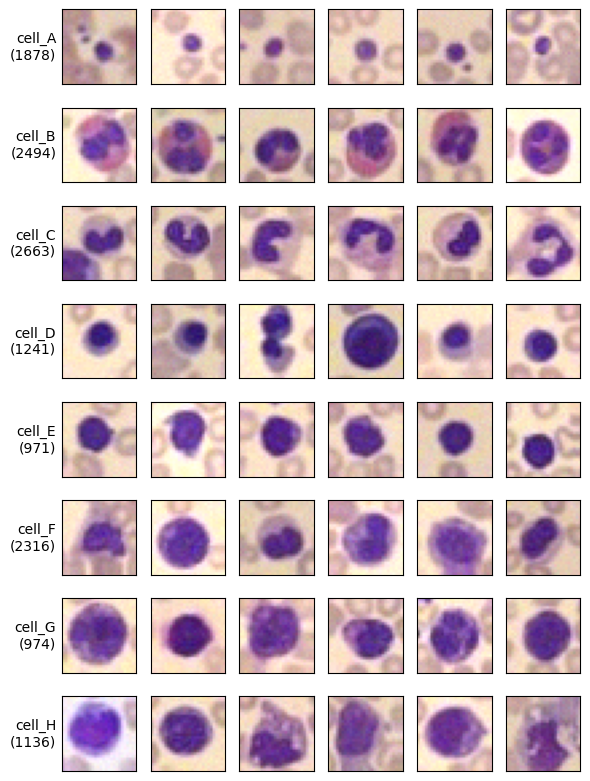

In [4]:
import matplotlib.pyplot as plt

classes = sorted(np.unique(y))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(classes), 6, figsize=(6, len(classes)))
for row, cls in zip(axes, classes):
    idx = rng.choice(np.flatnonzero(y == cls), size=6, replace=False)
    for ax, i in zip(row, idx):
        ax.imshow(train["images"][i])
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(f"{cls}\n({(y == cls).sum()})", rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()


## 3. A baseline model

Flatten each image into a vector of pixels and fit a random forest. This is just a
starting point — a small CNN (e.g. PyTorch) trained on the raw images will score
much higher. We hold out 20% to estimate the F1-macro before submitting.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

X = train["images"].reshape(len(train["images"]), -1) / 255.0   # (N, 28*28*3)
X_test = test["images"].reshape(len(test["images"]), -1) / 255.0

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
clf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)
clf.fit(X_tr, y_tr)
print("validation F1-macro: %.4f" % f1_score(y_val, clf.predict(X_val), average="macro"))

clf.fit(X, y)   # refit on all the training data before predicting the test set

validation F1-macro: 0.7315


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0)

## 4. Predict and write `submission.csv`

In [6]:
pred = clf.predict(X_test)
submission = pd.DataFrame({"image_id": test["image_id"], "label": pred})
submission.to_csv("submission.csv", index=False)
submission.head()

,image_id,label
0,img_002591,cell_C
1,img_001828,cell_D
2,img_015622,cell_G
3,img_010608,cell_F
4,img_008013,cell_F


## 5. Submit

Run the cell below to submit through the SDK, or upload `submission.csv` on the
challenge page.

In [8]:
result = client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"])
print(result)

{'submission_id': 9041, 'deploy': {'deployment_id': 8757, 'is_deployable': False, 'is_settled': False, 'is_uploadable': False, 'last_status_message': 'Deployment queued successfully', 'message': 'Deployment started successfully', 'phase': 'deployment', 'status': 'deploy_queue', 'status_update_ts': '2026-09-28T13:03:07.889967Z'}}


## 6. Where to go from here

The pixel-flattening baseline throws away the *spatial* structure of the image — that's
where most of the score is hiding. Work one step at a time: **change one thing → watch the
validation F1 → submit only if it improved.** Trust the held-out number, not the train score.

- **Look at more images.** Rerun the grid of section 2 with other seeds and look for anything odd — blurry crops, near-duplicates,
  mislabeled cells. F1-macro weights every class equally, so the rare ones matter most.

- **Train a small CNN (PyTorch).** A couple of conv + pooling layers already beats the random
  forest by a wide margin, because convolutions exploit the 2-D layout the baseline discards.
  Normalize inputs to `[0, 1]` (or per-channel mean/std) and use cross-entropy loss.

- **Train carefully.** Keep a stratified validation split and watch it every epoch.
  - *Learning rate* is the single most important knob — try a few values (e.g. 1e-2 … 1e-4).
  - Use **early stopping** and save the best-validation checkpoint.
  - Tune batch size and epochs; add dropout or weight decay if you overfit.

- **Augment the data.** Random flips, small rotations, and mild color jitter make the model
  robust to orientation and staining differences — cheap and almost always helps on microscopy.

- **Use a pretrained model.** Load a network pretrained on ImageNet (ResNet, EfficientNet, …),
  resize the 28×28 crops to its expected input, and **fine-tune** it on these cells. This is
  usually the biggest jump for the least effort.

Watch train vs. validation: if validation stalls while train keeps improving, you're
overfitting — stop early, augment more, or regularize.


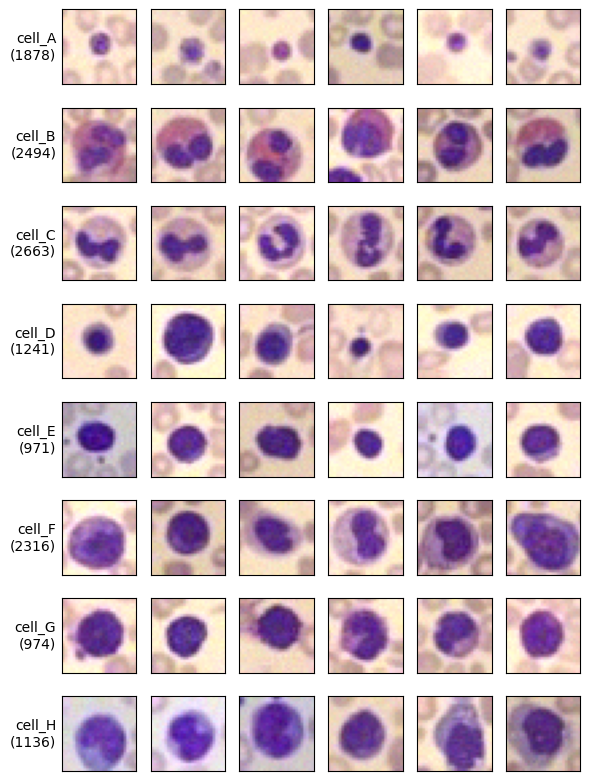

In [7]:
import matplotlib.pyplot as plt

classes = sorted(np.unique(y))
rng = np.random.default_rng(3)
fig, axes = plt.subplots(len(classes), 6, figsize=(6, len(classes)))
for row, cls in zip(axes, classes):
    idx = rng.choice(np.flatnonzero(y == cls), size=6, replace=False)
    for ax, i in zip(row, idx):
        ax.imshow(train["images"][i])
        ax.set_xticks([]); ax.set_yticks([])
    row[0].set_ylabel(f"{cls}\n({(y == cls).sum()})", rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()

Eingabe: (13673, 28, 28, 3)
$ O = \frac{N + 2P -K}{S} +1 $

In [70]:
from sklearn.preprocessing import LabelEncoder
import torch

X = train["images"].reshape(len(train["images"]), -1) / 255.0   # (N, 28*28*3)
X_test = test["images"].reshape(len(test["images"]), -1) / 255.0

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)

print(y_tr)
le = LabelEncoder()
le.fit(["cell_A", "cell_B", "cell_C", "cell_D", "cell_E", "cell_F", "cell_G", "cell_H"])
print(le.classes_)
y_tr_int = torch.tensor(le.transform(y_tr))
print(y_tr_int)
y_val_int = torch.as_tensor(le.transform(y_val))
print(np.shape(X_tr))
X_tr_torch = torch.tensor(X_tr, dtype=torch.float32).reshape(10938, 28, 28, 3).permute(0,3,1,2)
X_val_torch = torch.tensor(X_val, dtype=torch.float32).reshape(2735, 28, 28, 3).permute(0,3,1,2)

['cell_F' 'cell_B' 'cell_D' ... 'cell_C' 'cell_F' 'cell_F']
['cell_A' 'cell_B' 'cell_C' 'cell_D' 'cell_E' 'cell_F' 'cell_G' 'cell_H']
tensor([5, 1, 3,  ..., 2, 5, 5])
(10938, 2352)


In [69]:
print(np.shape(X_val))

(2735, 2352)


In [88]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
X_val_torch = X_val_torch.to(device)
y_val_int = y_val_int.to(device)

cuda


In [105]:
import torchvision.transforms as T
trns_rhf = T.RandomHorizontalFlip(p=1)

X_with_transformations = torch.stack(X_tr, [trns_rhf(img) for _ in range(4)])

AttributeError: 'RandomHorizontalFlip' object has no attribute 'ToTensor'

In [100]:
from torch import nn
from torch import optim
from torch.utils.data import DataLoader, TensorDataset
import copy

loss_cel = nn.CrossEntropyLoss()

class CNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.cnn = nn.Sequential(
      # 3 x 28 x 28
      nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      # 32 x 14 x 14
      nn.MaxPool2d(2),
      nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      # 64 x 7 x 7
      nn.MaxPool2d(2),
      nn.Conv2d(64, 128, 3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(2),
      # 128 x 3 x 3
      nn.Flatten(),
      nn.Linear(1152, 128),
      nn.ReLU(),
      nn.Linear(128, 8))

  def forward(self, x):
    return self.cnn(x)

def train_one_epoch(model, loader, opt):
  model.train()
  total = 0.0
  for (xb,yb) in loader:
    xb, yb = xb.to(device), yb.to(device)
    opt.zero_grad()
    loss = loss_cel(model(xb), yb)
    loss.backward()
    opt.step()
    total += loss.item() * len(xb)
  return total/ len(loader.dataset)

def evaluate(model, X, y):
  model.eval()
  pred = model(X)
  with torch.no_grad():
    loss = loss_cel(pred, y)
    kept_pct = (pred.argmax(1) == y).float().mean()
  return (loss, kept_pct)


cnn_model = CNN().to(device)
opt = optim.Adam(cnn_model.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(X_tr_torch, y_tr_int), batch_size = 64)

history, best_val, best_epoch, best_state = [], float("inf"), -1, None
for epoch in range(5):
  train_loss = train_one_epoch(cnn_model, loader, opt)
  val_loss, kept = evaluate(cnn_model, X_val_torch, y_val_int)
  history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "kept": kept})
  if val_loss < best_val:
    best_val = val_loss
    best_epoch = epoch
    best_state = copy.deepcopy(cnn_model.state_dict())
cnn_model.load_state_dict(best_state)

<All keys matched successfully>

In [102]:
print(history)

[{'epoch': 0, 'train_loss': 0.6672685892016519, 'val_loss': tensor(0.5051, device='cuda:0'), 'kept': tensor(0.8296, device='cuda:0')}, {'epoch': 1, 'train_loss': 0.4001451264429973, 'val_loss': tensor(0.3988, device='cuda:0'), 'kept': tensor(0.8545, device='cuda:0')}, {'epoch': 2, 'train_loss': 0.3207408812303695, 'val_loss': tensor(0.4018, device='cuda:0'), 'kept': tensor(0.8611, device='cuda:0')}, {'epoch': 3, 'train_loss': 0.27387124771096627, 'val_loss': tensor(0.3517, device='cuda:0'), 'kept': tensor(0.8826, device='cuda:0')}, {'epoch': 4, 'train_loss': 0.23072795920560338, 'val_loss': tensor(0.3312, device='cuda:0'), 'kept': tensor(0.8885, device='cuda:0')}]


In [101]:
cnn_model.eval()
with torch.no_grad():
    y_pred = cnn_model(X_val_torch).argmax(1).cpu().numpy()

print("validation F1-macro: %.4f" % f1_score(y_val_int.cpu(), y_pred, average="macro"))

validation F1-macro: 0.8713
